In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook
import matplotlib.cm as cm
from matplotlib.colorbar import ColorbarBase
from numpy.linalg import cholesky
from numpy.random import multivariate_normal
from scipy.optimize import curve_fit
from scipy.interpolate import UnivariateSpline

from scipy.integrate import quad, dblquad
from scipy.interpolate import interp1d
from scipy.integrate import cumulative_trapezoid
from scipy import interpolate
from scipy.special import kn  # Modified Bessel function of second kind

import os
import seaborn as sns
import pandas as pd
import importlib

#Plot param
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset']='dejavuserif'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.figsize'] = [8, 5]

## Jackknife samples

In [3]:
data = pd.read_csv("./data/cs2_WB.dat",sep=r"\s+",header=None)

In [4]:
import jk
importlib.reload(jk)
from jk import jackknife_statistics

jk_stats = jackknife_statistics(data)
jk_cov = jk_stats['cov_matrix']
jk_corr = jk_stats['corr_matrix']


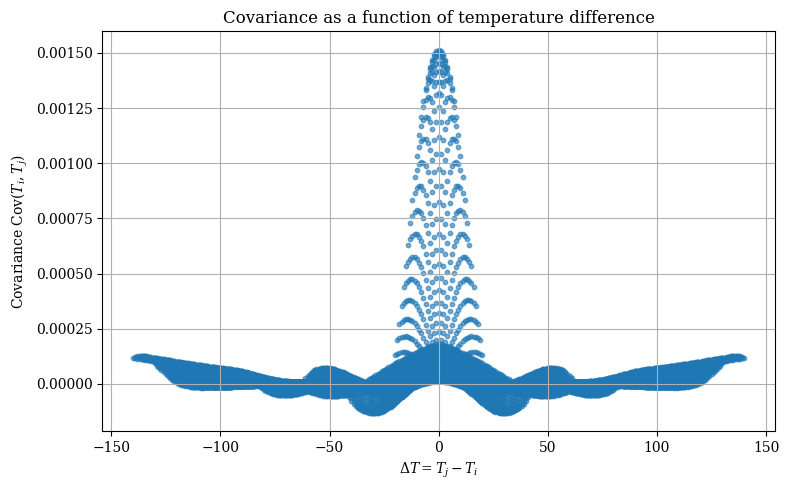

In [5]:
T = data.iloc[:, 0].values
delta_T = T[np.newaxis, :] - T[:, np.newaxis]  # shape: (n_T, n_T)

# Flatten both matrices
delta_T_flat = delta_T.flatten()
cov_flat = jk_cov.flatten()

# Plot covariance vs. ΔT
plt.figure(figsize=(8, 5))
plt.scatter(delta_T_flat, cov_flat, s=10, alpha=0.6)
plt.xlabel(r'$\Delta T = T_j - T_i$')
plt.ylabel(r'Covariance $\mathrm{Cov}(T_i, T_j)$')
plt.title("Covariance as a function of temperature difference")
plt.grid(True)
plt.tight_layout()

plt.savefig('./images/jk_cov_matrix.png')
plt.show()


/tmp/ipykernel_447967/667505201.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 141)


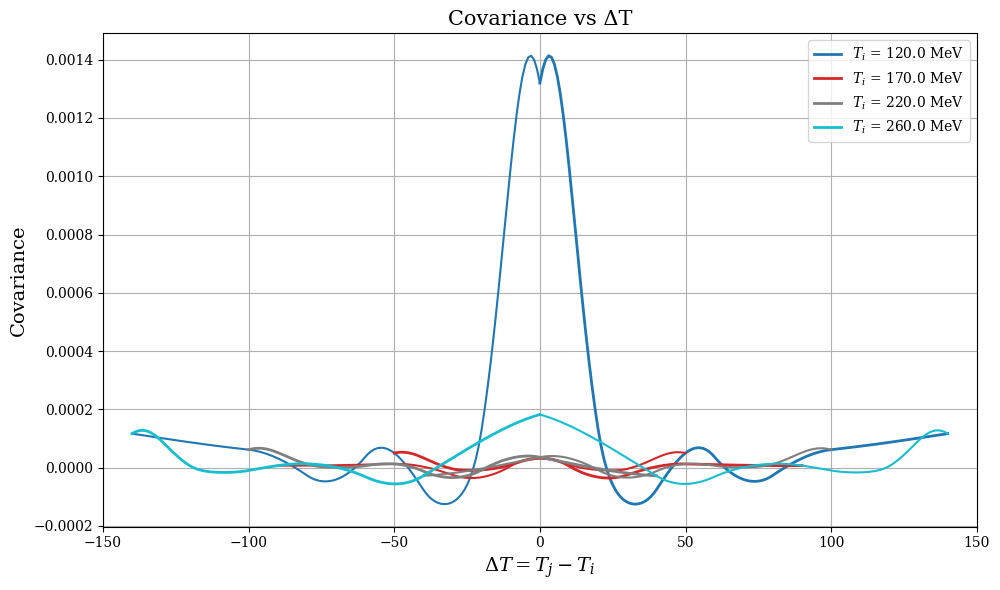

In [6]:
#plot slices

plt.figure(figsize=(10, 6))

rows_to_plot = [0, 50, 100, 140]
cmap = cm.get_cmap('tab10', 141)  
colors = [cmap(i) for i in range(141)]
#print(len(colors))

for i in rows_to_plot:
    color = colors[i] 
    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    cov_row = jk_cov[i, :]

    plt.plot(delta_T_plus, jk_cov[:, i], color=color, label=rf"$T_i$ = {T[i]:.1f} MeV", linewidth=2)
    plt.plot(delta_T_minus, jk_cov[:, i], color=color)

plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Covariance', fontsize=14)
plt.title('Covariance vs ΔT', fontsize=15)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.xlim(-150, 150)
plt.savefig("./images/covariance_slices.png")
plt.show()

In [7]:
def gaussian(x, sigma, l):
    return sigma * np.exp(-(x**2) / (2 * l**2))

sigma_fit_vec = []
l_fit_vec = []

with open("./data/gaussian_jk_fit_results.dat", "w") as f:
    f.write("# T    sigma    l\n")
    
    for i in range(len(T)):
        delta_T_plus = T - T[i]
        delta_T_minus = T[i] - T
        delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])
        cov_row = np.concatenate([jk_cov[i, ::-1], jk_cov[i, :]])

        try:
            #p0: initial guess for the parameters
            # Here, we use the diagonal element as the initial guess for sigma and a fixed value for l
            popt, _ = curve_fit(gaussian, delta_T, cov_row, p0=[jk_cov[i, i], 10])
            # unpacks the two fitted parameters from popt:
            sigma_fit, l_fit = popt
        except RuntimeError:
            sigma_fit, l_fit = np.nan, np.nan

        sigma_fit_vec.append(sigma_fit)
        l_fit_vec.append(l_fit)

        f.write(f"{T[i]}  {sigma_fit}  {l_fit}\n")

/tmp/ipykernel_447967/570921105.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', len(rows_to_plot))


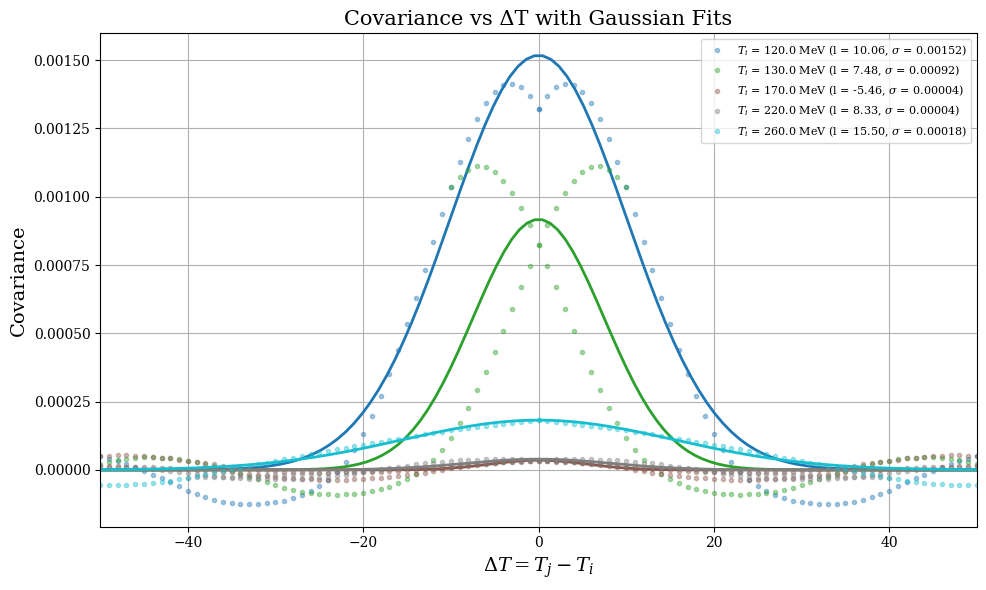

In [8]:
rows_to_plot = [0, 10, 50, 100, 140]
cmap = cm.get_cmap('tab10', len(rows_to_plot))
colors = [cmap(i) for i in range(len(rows_to_plot))]

plt.figure(figsize=(10, 6))

for idx, i in enumerate(rows_to_plot):
    # ΔT for both sides
    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])  # symmetric
    cov_row = np.concatenate([jk_cov[i, ::-1], jk_cov[i, :]])  # match order

    # Fit Gaussian
    popt, pcov = curve_fit(gaussian, delta_T, cov_row, p0=[jk_cov[i, i], 10])
    sigma_fit, l_fit = popt

    # Plot data
    plt.plot(delta_T, cov_row, 'o', markersize=3, color=colors[idx], alpha=0.4,
             label=rf"$T_i$ = {T[i]:.1f} MeV (l = {l_fit:.2f}, $\sigma$ = {sigma_fit:.5f})")
    
    # Plot fitted Gaussian
    x_fit = np.linspace(delta_T.min(), delta_T.max(), 300)
    plt.plot(x_fit, gaussian(x_fit, *popt), '-', color=colors[idx], linewidth=2)

plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Covariance', fontsize=14)
plt.title('Covariance vs ΔT with Gaussian Fits', fontsize=15)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.xlim(-50, 50)
plt.savefig("./images/covariance_gaussian_fits.png")
plt.show()

/tmp/ipykernel_447967/3425726259.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')  # continuous colormap


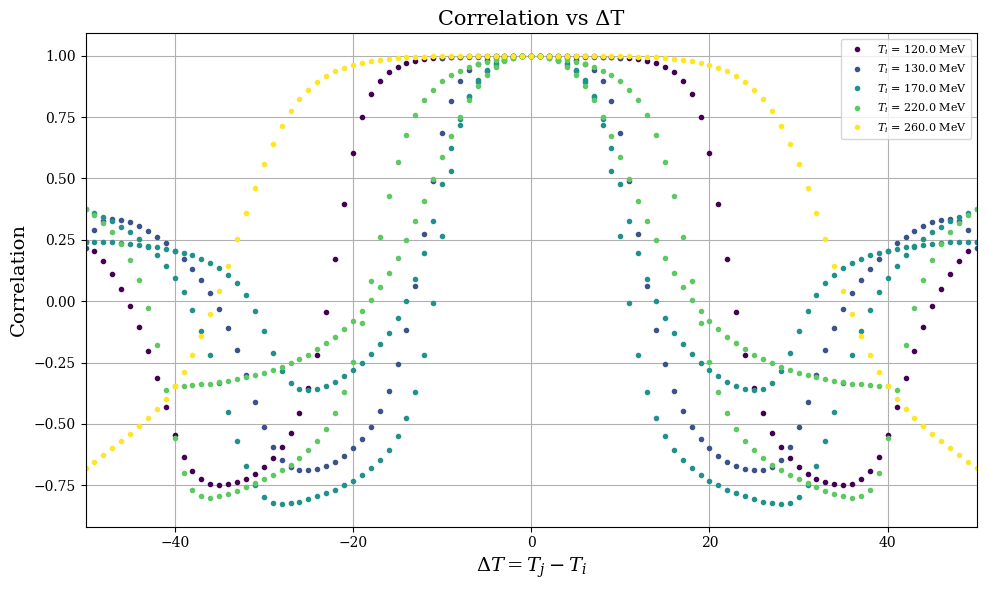

In [9]:
#plot corr matrix

plt.figure(figsize=(10, 6))

rows_to_plot = [0, 10, 50, 100, 140]
""" cmap = cm.get_cmap('viridis', 141)  # or 'coolwarm'
colors = [cmap(i) for i in range(141)] """
#print(len(colors))

cmap = cm.get_cmap('viridis')  # continuous colormap
num_rows = len(rows_to_plot)

for idx, i in enumerate(rows_to_plot):
    color = cmap(idx / (num_rows - 1))

    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])  # symmetric
    corr_row = np.concatenate([jk_corr[i, ::-1], jk_corr[i, :]])

    plt.plot(delta_T_plus, jk_corr[i, :], 'o', markersize=3, color=color, label=rf"$T_i$ = {T[i]:.1f} MeV")
    plt.plot(delta_T_minus, jk_corr[i, :], 'o', markersize=3, color=color)
    #plt.plot(delta_T, corr_row, linewidth=2)


plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Correlation', fontsize=14)
plt.title('Correlation vs ΔT', fontsize=15)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.xlim(-50, 50)
plt.savefig("./images/corr_slices.png")
plt.show()